# AF7: Redes Nuronales Artificiales

Hora: N1-N3



*   Reynaldo Aldape Sonora 2028750
*   Sergio Daniel Suárez Aguirre 2127902
*   Angel Esteban Pedraza Gomez 2097528
*   Emilio David Cerda Salazar 2070100

*   Alberto Araujo Martinez 2025718



### 📚 Explicación: Importar librerías

Se cargan las herramientas necesarias para construir y probar la red neuronal:

- `tensorflow as tf`: framework principal de aprendizaje automático. Keras viene integrado en él.
- `mnist`: conjunto de datos clásico de imágenes de dígitos escritos a mano (0 al 9).
- `Sequential`: tipo de modelo de Keras donde las capas se apilan una tras otra, en orden.
- `Dense`: capa totalmente conectada, en la que cada neurona recibe la salida de todas las neuronas de la capa anterior.
- `Flatten`: convierte una imagen 2D en un vector 1D para poder pasarla a capas `Dense`.
- `matplotlib.pyplot as plt`: para mostrar las imágenes de prueba.
- `numpy as np`: manejo de arreglos; se usa para ajustar la forma de la imagen y para obtener la clase predicha.

Esta celda no imprime nada; solo deja todo listo.

In [ ]:
#Cargar librerias (Keras y TensorFlow)

In [ ]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
import matplotlib.pyplot as plt
import numpy as np

### 📚 Explicación: Cargar los datos (MNIST)

`mnist.load_data()` descarga el dataset (solo la primera vez) y lo devuelve ya dividido en dos grupos:

- **Entrenamiento:** `train_data` (imágenes) y `train_labels` (el dígito correcto de cada una).
- **Prueba:** `test_data` y `test_label`, con los mismos elementos pero de imágenes que el modelo **nunca verá al entrenar**.

Cada imagen es una cuadrícula de 28×28 píxeles en escala de grises, con valores enteros entre 0 (negro) y 255 (blanco). El dataset trae 60,000 imágenes de entrenamiento y 10,000 de prueba.

**Resultado obtenido:** el mensaje `Downloading data from ...mnist.npz` solo indica que se descargó el archivo del dataset; no es una métrica.

In [ ]:
#Cargar datos (load_data() de la librería Keras)

In [ ]:
(train_data, train_labels), (test_data, test_label) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### 📚 Explicación: Preprocesamiento (normalización)

`train_data / 255.0` y `test_data / 255.0` dividen todos los píxeles entre 255, de modo que sus valores pasan del rango 0–255 al rango **0–1**.

Esto es necesario porque las redes neuronales aprenden más rápido y de forma más estable cuando las entradas son pequeñas y están en una escala uniforme. Además, se aplica **la misma transformación** a entrenamiento y a prueba; si no, el modelo recibiría en la prueba datos con una escala distinta a la que aprendió.

Esta celda no imprime nada.

In [ ]:
#Reprocesamiento de datos (Normalización)

In [ ]:
train_data = train_data / 255.0
test_data = test_data / 255.0

### 📚 Explicación: Definir, compilar y entrenar el modelo

**1. Arquitectura (`Sequential`)**
- `Flatten(input_shape=(28, 28))`: aplana cada imagen de 28×28 en un vector de 784 valores. Es la capa de entrada.
- `Dense(128, activation='relu')`: capa oculta de 128 neuronas. ReLU deja pasar los valores positivos y convierte los negativos en 0, lo que permite aprender relaciones no lineales.
- `Dense(10, activation='softmax')`: capa de salida con 10 neuronas, una por dígito. Softmax convierte las salidas en **probabilidades que suman 1**.

**2. Compilación (`compile`)**
- `optimizer='adam'`: algoritmo que ajusta los pesos de la red y adapta su velocidad de aprendizaje.
- `loss='sparse_categorical_crossentropy'`: función de pérdida para clasificación de varias clases cuando las etiquetas son números enteros (0–9) y no vectores one-hot.
- `metrics=['accuracy']`: porcentaje de aciertos que se reporta en cada época.

**3. Entrenamiento (`fit`)**
- `epochs=10`: la red recorre los 60,000 datos de entrenamiento 10 veces.
- `batch_size=32`: los pesos se actualizan cada 32 imágenes, por lo que cada época tiene 60,000 / 32 = **1875 pasos** (el `1875/1875` que se ve en la salida).
- `historial` guarda la pérdida y la precisión de cada época, por si se quiere graficar después.

**Resultados obtenidos:**
- En la época 1, la precisión fue de **0.9271** con una pérdida de 0.2594.
- En la época 10, la precisión subió a **0.9948** (≈ 99.5 %) y la pérdida bajó a 0.0167.
- La mejora fue constante en cada época, lo que indica que la red aprendió bien los patrones de los dígitos.
- Estas métricas son sobre los datos de **entrenamiento**, así que no garantizan el mismo rendimiento con imágenes nuevas; para eso sirve la prueba de la celda siguiente.
- El `UserWarning` sobre `input_shape` no es un error: Keras sugiere declarar la entrada con un objeto `Input(shape)` en lugar de pasarla a `Flatten`, pero el modelo funciona igual.

In [ ]:
#Selección y prueba del modelo

In [ ]:
modelo = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

historial = modelo.fit(
    train_data,
    train_labels,
    epochs=10,
    batch_size=32
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9271 - loss: 0.2594
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9668 - loss: 0.1111
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9773 - loss: 0.0761
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9821 - loss: 0.0575
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9860 - loss: 0.0456
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9886 - loss: 0.0355
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9910 - loss: 0.0283
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9926 - loss: 0.0235
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9940 - loss: 0.0194
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9948 - loss: 0.0167


### 📚 Explicación: Prueba del modelo con imágenes individuales

Se eligen 5 imágenes del conjunto de **prueba** (índices 0, 7, 11, 67 y 100). Para cada una, el ciclo `for` hace lo siguiente:

1. Toma la imagen y su etiqueta real (`imagen_individual`, `valor_real`).
2. `np.expand_dims(..., axis=0)` agrega una dimensión extra: el modelo espera un *lote* de imágenes con forma `(1, 28, 28)`, aunque sea una sola.
3. `modelo.predict(...)` devuelve las 10 probabilidades, una por dígito.
4. `np.argmax(...)` toma la posición de la probabilidad más alta, que es el dígito que predice el modelo.
5. `plt.imshow(..., cmap='Purples')` muestra la imagen y `plt.colorbar` agrega la escala de intensidad de los píxeles.
6. El título sale en **verde** si la predicción coincide con el valor real y en **rojo** si falla.
7. `plt.axis('off')` oculta los ejes para que solo se vea el dígito.
8. Se imprimen el dígito predicho, el real y un mensaje: `GG` si acertó o `F` si se equivocó.

**Resultados obtenidos:**

| Índice | Predicho | Real | Resultado |
|---|---|---|---|
| 0 | 7 | 7 | GG |
| 7 | 9 | 9 | GG |
| 11 | 6 | 6 | GG |
| 67 | 4 | 4 | GG |
| 100 | 6 | 6 | GG |

El modelo acertó las **5 de 5** imágenes de prueba, coherente con su alta precisión en el entrenamiento. Son solo 5 ejemplos, así que sirven como demostración y no como medida completa del desempeño (para eso se evaluaría con `modelo.evaluate` sobre las 10,000 imágenes de prueba).

In [ ]:
#Prueba del modelo

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


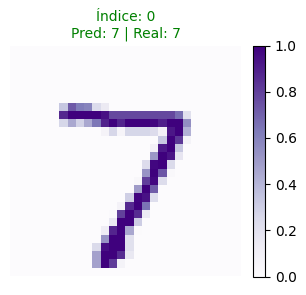

--- Resultado para el índice 0 ---
Dígito predicho por el modelo : 7
Dígito real (etiqueta)       : 7
 Resultado: GG 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


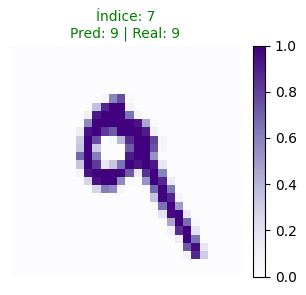

--- Resultado para el índice 7 ---
Dígito predicho por el modelo : 9
Dígito real (etiqueta)       : 9
 Resultado: GG 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


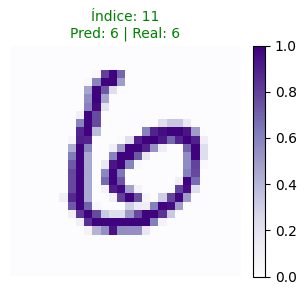

--- Resultado para el índice 11 ---
Dígito predicho por el modelo : 6
Dígito real (etiqueta)       : 6
 Resultado: GG 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


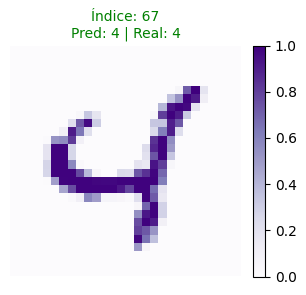

--- Resultado para el índice 67 ---
Dígito predicho por el modelo : 4
Dígito real (etiqueta)       : 4
 Resultado: GG 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


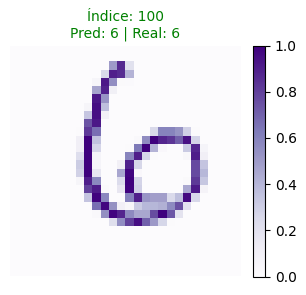

--- Resultado para el índice 100 ---
Dígito predicho por el modelo : 6
Dígito real (etiqueta)       : 6
 Resultado: GG 



In [ ]:
indices_a_probar = [0, 7, 11, 67, 100]

for idx in indices_a_probar:
    imagen_individual = test_data[idx]
    valor_real = test_label[idx]

    imagen_para_modelo = np.expand_dims(imagen_individual, axis=0)
    prediccion_probabilidades = modelo.predict(imagen_para_modelo)
    pred_clase = np.argmax(prediccion_probabilidades)

    plt.figure(figsize=(4, 3))

    im = plt.imshow(imagen_individual, cmap='Purples')

    plt.colorbar(im, fraction=0.046, pad=0.04)

    color_texto = 'green' if pred_clase == valor_real else 'red'

    plt.title(f"Índice: {idx}\nPred: {pred_clase} | Real: {valor_real}", color=color_texto, fontsize=10)
    plt.axis('off')
    plt.show()

    print(f"--- Resultado para el índice {idx} ---")
    print(f"Dígito predicho por el modelo : {pred_clase}")
    print(f"Dígito real (etiqueta)       : {valor_real}")
    if pred_clase == valor_real:
        print(" Resultado: GG \n")
    else:
        print(" Resultado: F \n")